# Analyse métier - Étoile CRM et segmentation RFM

**Table Druid :** mart_customer_rfm  
**Grain :** Une ligne par customer_unique_id, calculée sur les commandes livrées disponibles au dernier rafraîchissement du mart

Ce notebook exécute cinquante visuels depuis la table Druid dénormalisée indiquée ci-dessus. La première cellule détecte une connexion accessible depuis le noyau Python : `http://127.0.0.1:25019/druid/v2/sql` sur l’hôte ou `http://druid-router:8888/druid/v2/sql` dans Docker. Pour imposer une URL, définir `DRUID_SQL_URL_OVERRIDE` ou la variable d’environnement `DRUID_SQL_URL`.

**Limite du modèle :** RFM ne couvre que les commandes livrées et utilise une date de référence au moment de la construction. Ce mart est un état courant, pas un historique de snapshots : il ne mesure pas directement la rétention, le churn observé ni la valeur à vie. Les segments par quintiles sont calculés dans le notebook à partir du snapshot chargé, ils ne sont pas des colonnes stockées.

**Source du modèle :** [20_build_ebrasil_warehouse.py](https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py), blob GitHub `8b553b3970eb8f3f5804ac0072569cfade518c57`. Le script produit les six tables dénormalisées ; `docker/ebrasil-druid/ingest.py` les ingère sous les mêmes noms, sans rollup. Au démarrage, le notebook contrôle les six tables et les colonnes utilisées par ses graphiques via `INFORMATION_SCHEMA.COLUMNS`, ainsi que la présence de lignes dans sa table. Aucune donnée de démonstration ni dimension séparée n’est utilisée. La compatibilité du schéma est contrôlée ; la provenance des lignes dépend de l’initialisation eBrasil du dépôt.


In [1]:
import os
import socket
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# None : sélection automatique depuis le noyau Python, indépendamment du navigateur.
# Pour imposer une adresse, renseigner ceci ou la variable d'environnement DRUID_SQL_URL.
DRUID_SQL_URL_OVERRIDE = None
HOST_SQL_URL = "http://127.0.0.1:25019/druid/v2/sql"
DOCKER_SQL_URL = "http://druid-router:8888/druid/v2/sql"
TABLE = "mart_customer_rfm"
MODEL_TABLES = ["fact_logistics","fact_order","fact_order_item","fact_payment","fact_review","mart_customer_rfm"]
REQUIRED_COLUMNS = ["average_order_value","customer_city","customer_state","customer_unique_id","customer_zip_code","frequency","last_purchase_date_calendar_date","last_purchase_date_year","last_purchase_time_day_part","monetary","recency_days"]
MODEL_SOURCE = "https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py"
MODEL_SOURCE_BLOB_SHA = "8b553b3970eb8f3f5804ac0072569cfade518c57"

def normalize_sql_url(value):
    parsed = urlsplit(value.strip())
    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("DRUID_SQL_URL doit être une URL HTTP complète, sans syntaxe Markdown.")
    if parsed.username or parsed.password or parsed.query or parsed.fragment:
        raise ValueError("Ne pas inclure d'identifiants, de paramètres ou de fragment dans DRUID_SQL_URL.")
    netloc = parsed.netloc
    if parsed.hostname == "druid-router" and parsed.port == 25019:
        warnings.warn("Port corrigé : druid-router utilise 8888 ; 25019 est le port de l'hôte.")
        netloc = "druid-router:8888"
    if parsed.hostname in ("localhost", "127.0.0.1") and parsed.port == 8888:
        warnings.warn("Port hôte corrigé selon le dépôt : 127.0.0.1:25019.")
        netloc = "127.0.0.1:25019"
    path = parsed.path.rstrip("/") or "/druid/v2/sql"
    if path != "/druid/v2/sql":
        raise ValueError("Le point d'accès attendu est /druid/v2/sql.")
    return urlunsplit((parsed.scheme, netloc, path, "", ""))

def select_druid_url():
    explicit = DRUID_SQL_URL_OVERRIDE or os.getenv("DRUID_SQL_URL", "").strip()
    try:
        socket.getaddrinfo("druid-router", 8888)
        docker_dns = True
    except OSError:
        docker_dns = False
    in_docker = Path("/.dockerenv").exists() or docker_dns
    candidates = [DOCKER_SQL_URL, HOST_SQL_URL] if in_docker else [HOST_SQL_URL, DOCKER_SQL_URL]
    if explicit:
        candidates = [normalize_sql_url(explicit)]
    errors = []
    for url in candidates:
        try:
            response = requests.post(url, json={"query": "SELECT 1 AS connexion_ok", "resultFormat": "object"}, timeout=(3, 8))
            response.raise_for_status()
            result = response.json()
            if not isinstance(result, list) or not result or result[0].get("connexion_ok") != 1:
                raise ValueError("Ce service ne répond pas comme Druid SQL.")
            return url
        except (requests.RequestException, ValueError) as exc:
            errors.append(f"{url} : {exc}")
    raise ConnectionError(
        "Connexion Druid impossible depuis ce noyau Python.\nWindows : " + HOST_SQL_URL +
        "\nDocker du dépôt : " + DOCKER_SQL_URL +
        "\nVérifier druid-router et le réseau Docker. Corriger ou supprimer la variable DRUID_SQL_URL si elle est définie.\n" +
        "\n".join(errors)
    )

DRUID_SQL_URL = select_druid_url()

def druid_sql(sql):
    try:
        response = requests.post(DRUID_SQL_URL,
            json={"query": sql, "resultFormat": "object",
                  "context": {"sqlTimeZone": "UTC", "useApproximateCountDistinct": False}}, timeout=(5, 120))
    except requests.RequestException as exc:
        raise ConnectionError(f"Druid inaccessible à {DRUID_SQL_URL}. Relancer la cellule de connexion.") from exc
    if not response.ok:
        raise RuntimeError(f"Druid SQL HTTP {response.status_code}\nSQL : {sql}\n{response.text[:3000]}")
    data = response.json()
    if not isinstance(data, list):
        raise ValueError("Druid doit renvoyer une liste d'objets JSON.")
    return pd.DataFrame(data)

# Toutes les données analysées proviennent des tables dénormalisées exposées par Druid.
model_names = ", ".join("'" + name + "'" for name in MODEL_TABLES)
schema = druid_sql(
    'SELECT TABLE_NAME AS "table_name", COLUMN_NAME AS "column_name", DATA_TYPE AS "data_type" '
    "FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'druid' AND TABLE_NAME IN (" + model_names + ")"
)
if schema.empty:
    raise RuntimeError("Aucune étoile eBrasil dans Druid : exécuter l'initialisation du dépôt.")
missing_tables = set(MODEL_TABLES) - set(schema["table_name"])
if missing_tables:
    raise RuntimeError("Tables Druid manquantes : " + ", ".join(sorted(missing_tables)))
present_columns = set(schema.loc[schema["table_name"] == TABLE, "column_name"])
missing_columns = set(REQUIRED_COLUMNS) - present_columns
if missing_columns:
    raise RuntimeError(f"Schéma incompatible pour {TABLE}. Colonnes dénormalisées manquantes : " +
        ", ".join(sorted(missing_columns)) + ". Reconstruire avec 20_build_ebrasil_warehouse.py puis réingérer dans Druid.")
row_count = int(druid_sql(f'SELECT COUNT(*) AS lignes FROM "{TABLE}"').iloc[0]["lignes"])
if row_count == 0:
    raise RuntimeError(f"La table Druid {TABLE} est vide.")
print("Druid SQL :", DRUID_SQL_URL)
print(f"Table : {TABLE} | {row_count:,} lignes | {len(REQUIRED_COLUMNS)} colonnes contrôlées")
print("Source du modèle :", MODEL_SOURCE)
display(schema.loc[schema["table_name"] == TABLE].reset_index(drop=True))


Druid SQL : http://127.0.0.1:25019/druid/v2/sql
Table : mart_customer_rfm | 93,358 lignes | 11 colonnes contrôlées
Source du modèle : https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py


,table_name,column_name,data_type
0,mart_customer_rfm,__time,TIMESTAMP
1,mart_customer_rfm,customer_unique_id,VARCHAR
2,mart_customer_rfm,last_purchase,VARCHAR
3,mart_customer_rfm,last_purchase_date_key,VARCHAR
4,mart_customer_rfm,last_purchase_time_key,VARCHAR
5,mart_customer_rfm,customer_customer_id,VARCHAR
6,mart_customer_rfm,customer_zip_code,VARCHAR
7,mart_customer_rfm,customer_city,VARCHAR
8,mart_customer_rfm,customer_state,VARCHAR
9,mart_customer_rfm,customer_name_state,VARCHAR


## Préparation des quintiles RFM

Quintiles calculés localement à partir du snapshot chargé (limite : 200 000 clients). Le score de récence est inversé : R5 désigne les achats les plus récents. Ces classes relatives ne sont pas stockées dans Druid.

In [2]:
rfm=druid_sql('SELECT "customer_unique_id", "recency_days", "frequency", "monetary", "average_order_value", "customer_state", "customer_city", "customer_zip_code", "last_purchase_date_calendar_date", "last_purchase_date_year", "last_purchase_time_day_part" FROM "mart_customer_rfm"')
if rfm.empty: raise ValueError("Le mart RFM ne retourne aucune ligne.")
if len(rfm) != row_count:
    raise RuntimeError("Chargement RFM incomplet : relancer sur une table stable.")
rfm = rfm.sort_values("customer_unique_id").reset_index(drop=True)
for column in ("recency_days", "frequency", "monetary", "average_order_value"):
    rfm[column] = pd.to_numeric(rfm[column], errors="raise")
def quintile(values,reverse=False):
    ranks=values.rank(method="first",ascending=not reverse)
    return pd.qcut(ranks,q=5,labels=False,duplicates="drop").astype("Int64")+1
rfm["__rfm_r_score"]=quintile(rfm["recency_days"],reverse=True)
rfm["__rfm_f_score"]=quintile(rfm["frequency"])
rfm["__rfm_m_score"]=quintile(rfm["monetary"])
rfm["__rfm_segment"]="R"+rfm["__rfm_r_score"].astype(str)+" F"+rfm["__rfm_f_score"].astype(str)+" M"+rfm["__rfm_m_score"].astype(str)
rfm["__last_purchase_month"] = rfm["last_purchase_date_calendar_date"].astype("string").str.slice(0,7)
display(rfm.head())


,customer_unique_id,recency_days,frequency,monetary,average_order_value,customer_state,customer_city,customer_zip_code,last_purchase_date_calendar_date,last_purchase_date_year,last_purchase_time_day_part,__rfm_r_score,__rfm_f_score,__rfm_m_score,__rfm_segment,__last_purchase_month
0,0000366f3b9a7992bf8c76cfdf3221e2,3084,1,141.90,141.90,SP,cajamar,7787,2018-05-10,2018,morning,4,1,4,R4 F1 M4,2018-05
1,0000b849f77a49e4a4ce2b2a4ca5be3f,3087,1,27.19,27.19,SP,osasco,6053,2018-05-07,2018,morning,4,1,1,R4 F1 M1,2018-05
2,0000f46a3911fa3c0805444483337064,3510,1,86.22,86.22,SC,sao jose,88115,2017-03-10,2017,evening,1,1,2,R1 F1 M2,2017-03
3,0000f6ccb0745a6a4b88665a16c9f078,3294,1,43.62,43.62,PA,belem,66812,2017-10-12,2017,evening,2,1,1,R2 F1 M1,2017-10
4,0004aac84e0df4da2b147fca70cf8255,3261,1,196.89,196.89,SP,sorocaba,18040,2017-11-14,2017,evening,2,1,4,R2 F1 M4,2017-11


In [3]:
def build_chart_sql(spec):
    """Construit une requête Druid avec des alias délimités, y compris VALUE."""
    dim, metric, kind = spec["dim"], spec["metric"], spec["kind"]
    fields = [dim["sql"] + ' AS "x"']
    if dim.get("series"):
        fields.append(dim["series"] + ' AS "series"')
    fields.append(metric["sql"] + ' AS "value"')
    group_by = "1, 2" if dim.get("series") else "1"
    order_by = '"x"' if kind == "line" else '"value" DESC'
    table_name = TABLE.replace('"', '""')
    return ('SELECT ' + ', '.join(fields) + ' FROM "' + table_name +
            '" GROUP BY ' + group_by + ' ORDER BY ' + order_by + ' LIMIT 40')

def run_chart(spec):
    dim,metric,kind=spec["dim"],spec["metric"],spec["kind"]
    if dim["type"] == "client" or "__rfm_" in (dim["sql"] + (dim.get("series") or "")):
        xcol=dim["sql"].replace('"',""); frame=rfm.copy(); scol=(dim.get("series") or "").replace('"',"")
        if scol.startswith("SUBSTRING("): scol="__last_purchase_month"
        if xcol not in frame.columns: raise KeyError("Dimension RFM manquante: "+xcol)
        by=[xcol]+([scol] if scol else [])
        if metric["pandas"]=="customer_unique_id": grouped=frame.groupby(by,dropna=False)["customer_unique_id"].nunique().reset_index(name="value")
        else:
            agg="sum" if metric["pandas"]=="monetary" else "mean"
            grouped=frame.groupby(by,dropna=False)[metric["pandas"]].agg(agg).reset_index(name="value")
        if scol: grouped=grouped.pivot(index=xcol,columns=scol,values="value").fillna(0).head(25)
        else: grouped=grouped.sort_values("value",ascending=False).head(25).set_index(xcol)["value"]
    else:
        sql = build_chart_sql(spec)
        result=druid_sql(sql)
        if result.empty: print("Aucune donnée pour",spec["title"]); return
        if dim.get("series"): grouped=result.pivot_table(index="x",columns="series",values="value",aggfunc="sum",fill_value=0).head(25)
        else:
            result=result.sort_values("x" if kind=="line" else "value",ascending=(kind=="line")); grouped=result.set_index("x")["value"].head(40)
    fig,ax=plt.subplots(figsize=(10,5))
    if isinstance(grouped,pd.DataFrame):
        if kind=="heatmap":
            img=ax.imshow(grouped.values,aspect="auto",cmap="YlGnBu")
            ax.set_yticks(range(len(grouped.index))); ax.set_yticklabels([str(v) for v in grouped.index])
            ax.set_xticks(range(len(grouped.columns))); ax.set_xticklabels([str(v) for v in grouped.columns],rotation=45,ha="right")
            fig.colorbar(img,ax=ax,label=metric["label"])
        else: grouped.plot(kind="bar",stacked=True,ax=ax,colormap="tab20"); ax.legend(title="Série",bbox_to_anchor=(1.02,1),loc="upper left")
    elif kind=="line": grouped.plot(kind="line",marker="o",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    elif kind=="scatter": ax.scatter(pd.to_numeric(pd.Series(grouped.index),errors="coerce"),grouped.values,color="#148A8A",alpha=.75)
    else: grouped.plot(kind="bar",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    ax.set_title(spec["title"]); ax.set_xlabel(dim["label"]); ax.set_ylabel(metric["label"])
    fig.tight_layout(); plt.show(); plt.close(fig)


## 1. Segmentation RFM des clients

Construire des quintiles relatifs de récence, fréquence et valeur à partir du snapshot courant pour faire apparaître les profils prioritaires.

**Drill-down :** Récence (croissante inversée) x fréquence x monetary; segment > client > état/ville; filtre de taille du segment.

Visuel 1 - Segmentation RFM des clients - Segment RFM quintiles (calcul notebook)


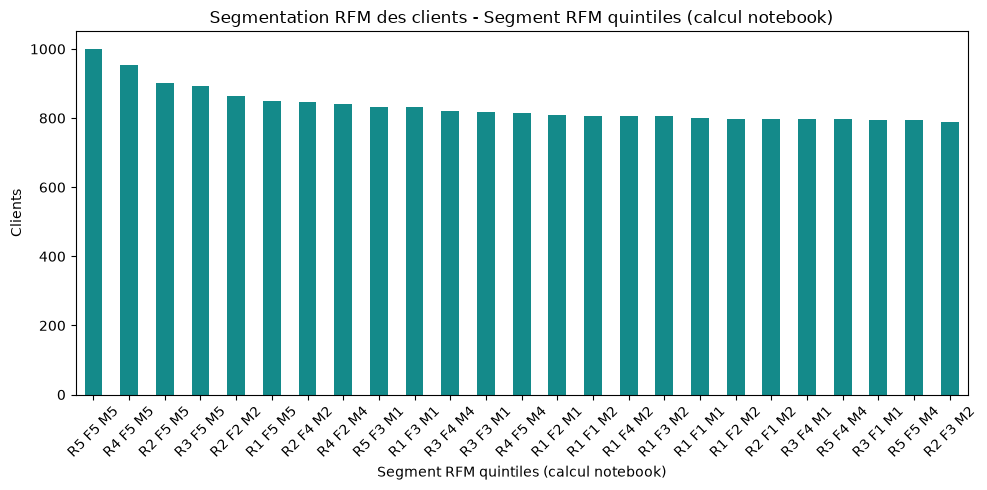

Visuel 2 - Segmentation RFM des clients - Score récence


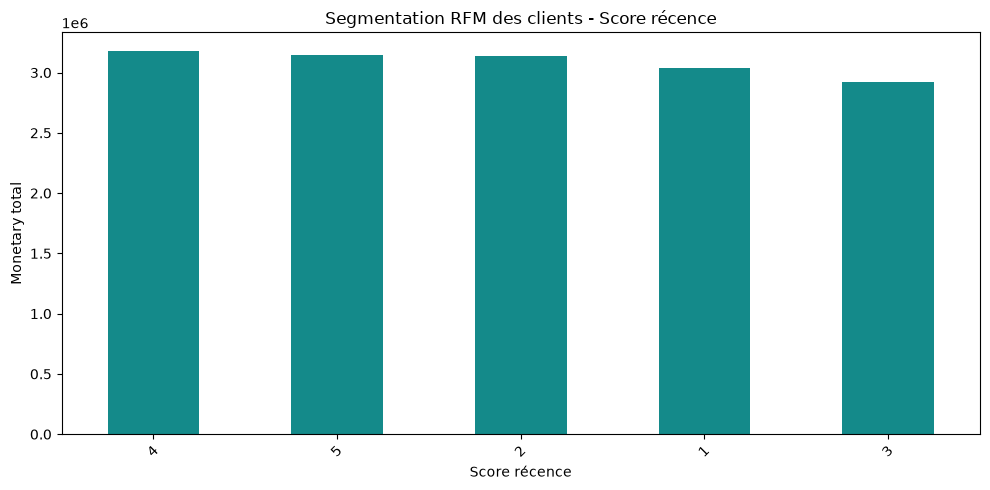

Visuel 3 - Segmentation RFM des clients - Score fréquence


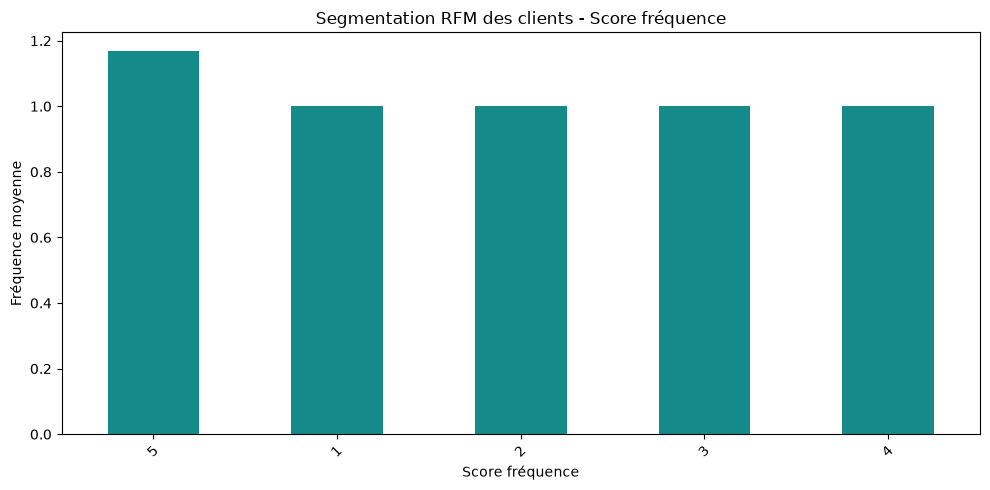

Visuel 4 - Segmentation RFM des clients - Score monetary


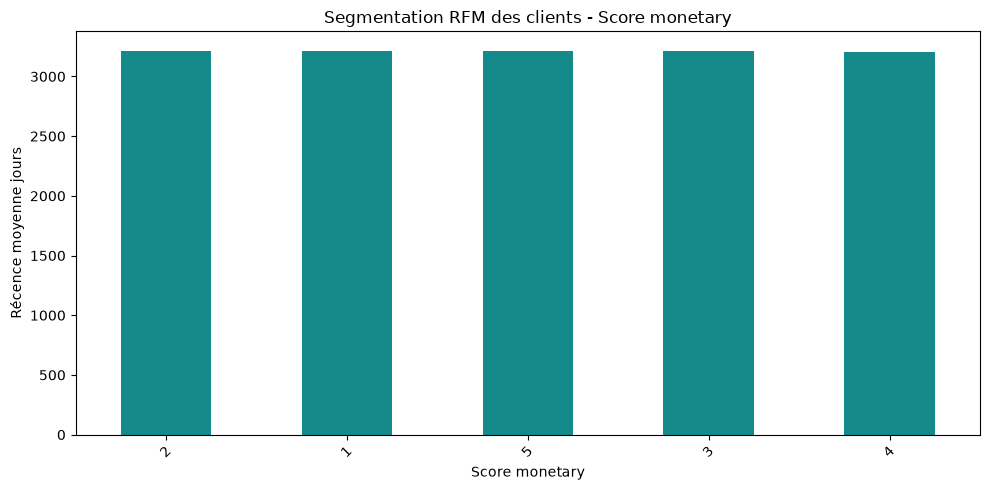

Visuel 5 - Segmentation RFM des clients - Récence jours


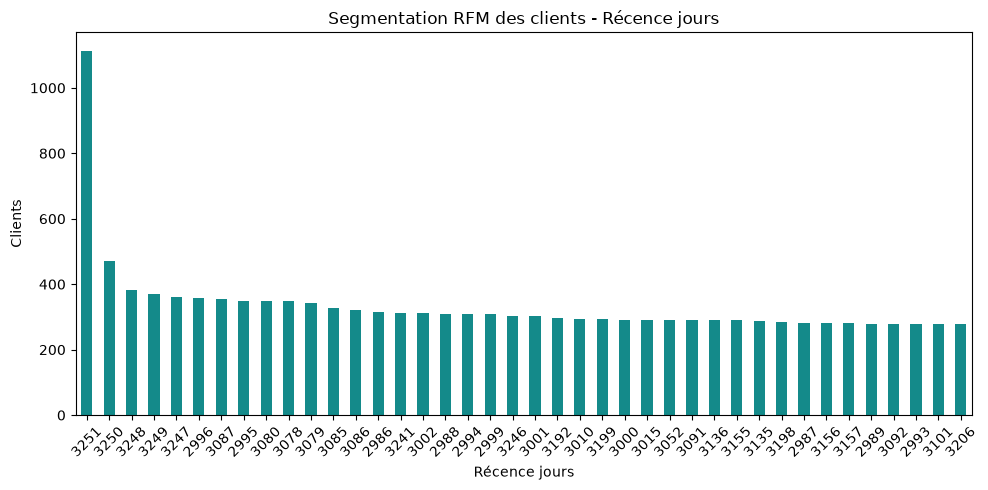

Visuel 6 - Segmentation RFM des clients - Fréquence commandes


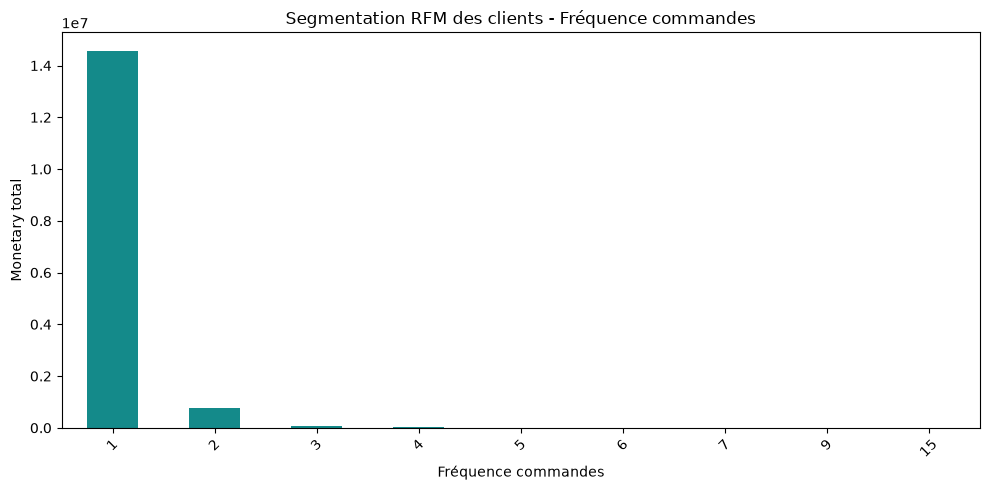

Visuel 7 - Segmentation RFM des clients - Monetary


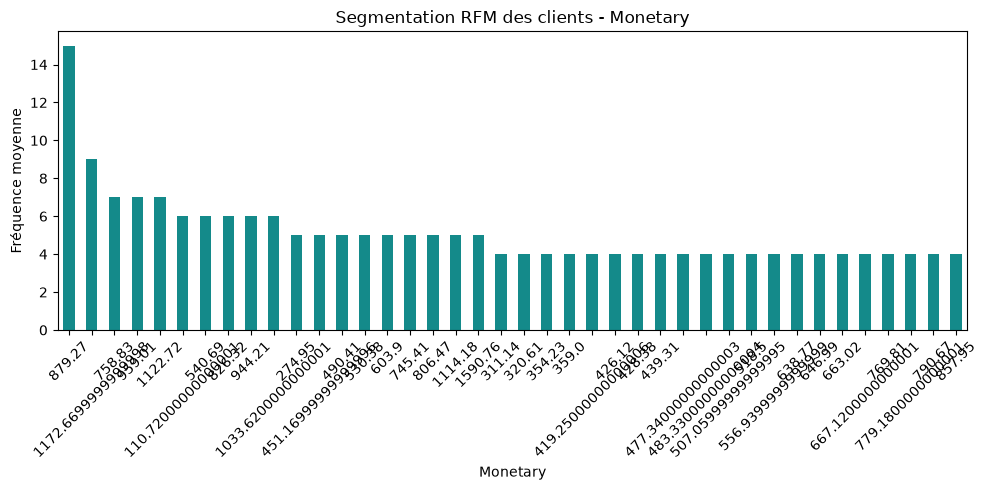

Visuel 8 - Segmentation RFM des clients - État client


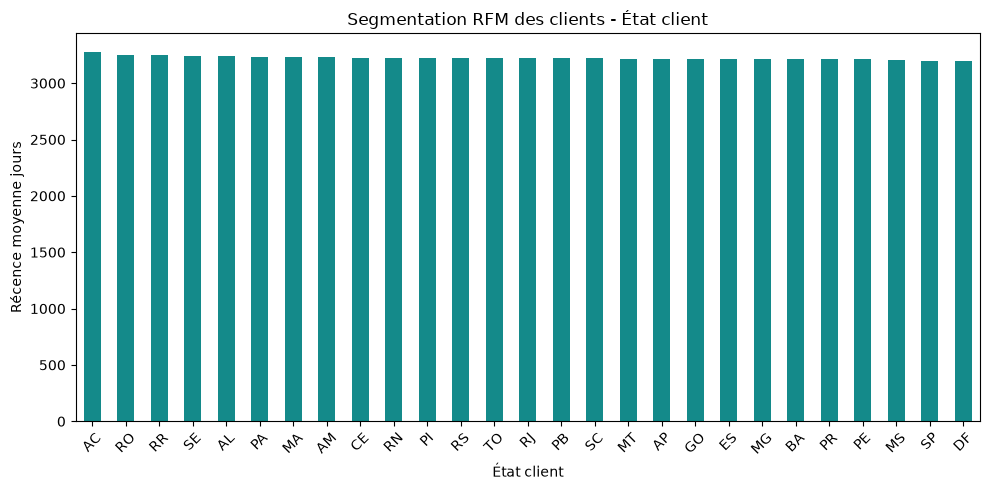

Visuel 9 - Segmentation RFM des clients - Ville client


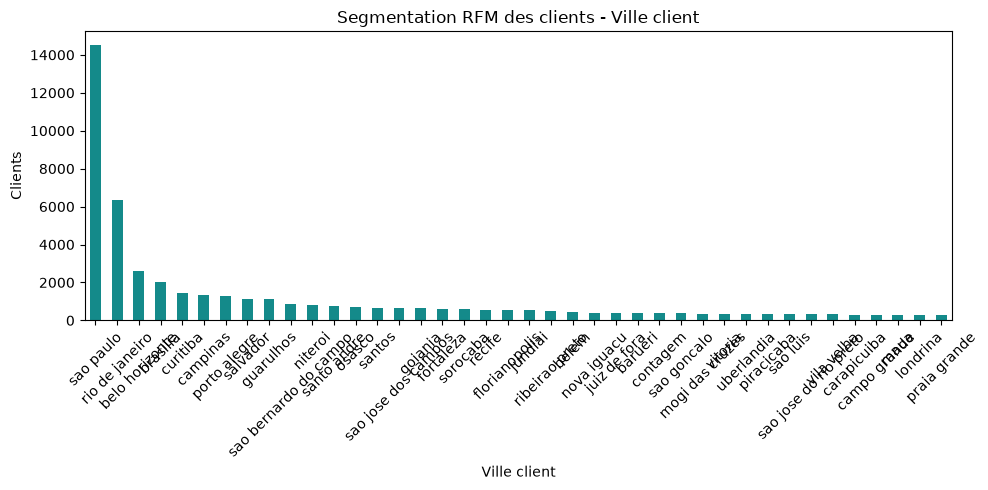

Visuel 10 - Segmentation RFM des clients - Dernier achat par mois


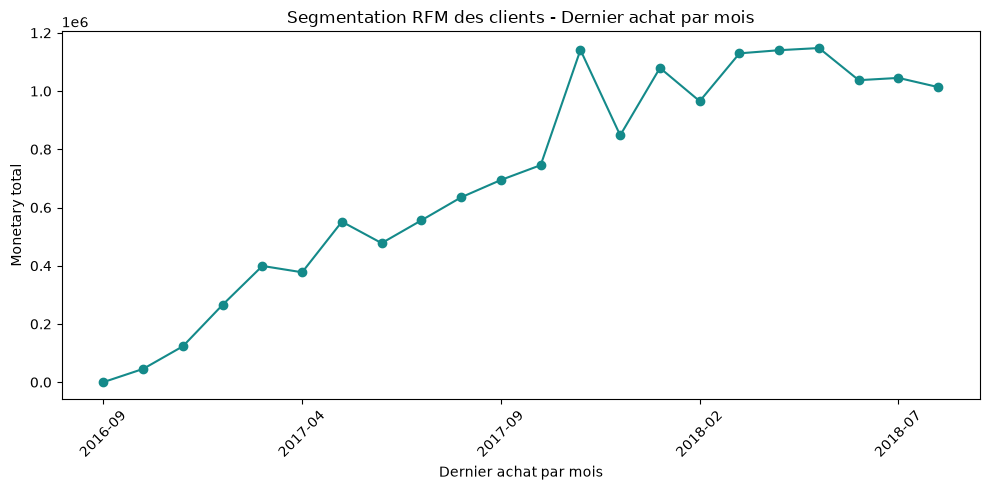

In [4]:
CHARTS=[
  {
    "n": 1,
    "title": "Segmentation RFM des clients - Segment RFM quintiles (calcul notebook)",
    "dim": {
      "label": "Segment RFM quintiles (calcul notebook)",
      "sql": "__rfm_segment",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Segmentation RFM des clients - Score récence",
    "dim": {
      "label": "Score récence",
      "sql": "__rfm_r_score",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Segmentation RFM des clients - Score fréquence",
    "dim": {
      "label": "Score fréquence",
      "sql": "__rfm_f_score",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Segmentation RFM des clients - Score monetary",
    "dim": {
      "label": "Score monetary",
      "sql": "__rfm_m_score",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Récence moyenne jours",
      "sql": "AVG(\"recency_days\")",
      "pandas": "recency_days"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Segmentation RFM des clients - Récence jours",
    "dim": {
      "label": "Récence jours",
      "sql": "\"recency_days\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Segmentation RFM des clients - Fréquence commandes",
    "dim": {
      "label": "Fréquence commandes",
      "sql": "\"frequency\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Segmentation RFM des clients - Monetary",
    "dim": {
      "label": "Monetary",
      "sql": "\"monetary\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Segmentation RFM des clients - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Récence moyenne jours",
      "sql": "AVG(\"recency_days\")",
      "pandas": "recency_days"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Segmentation RFM des clients - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 10,
    "title": "Segmentation RFM des clients - Dernier achat par mois",
    "dim": {
      "label": "Dernier achat par mois",
      "sql": "SUBSTRING(\"last_purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "line"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 2. Concentration de valeur et clients à forte contribution

Mesurer la concentration du Monetary et distinguer les clients qui contribuent le plus du reste de la base.

**Drill-down :** Monetary total > quintile/segment > client > géographie; comparer effectif et contribution.

Visuel 1 - Concentration de valeur et clients à forte contribution - Segment RFM quintiles


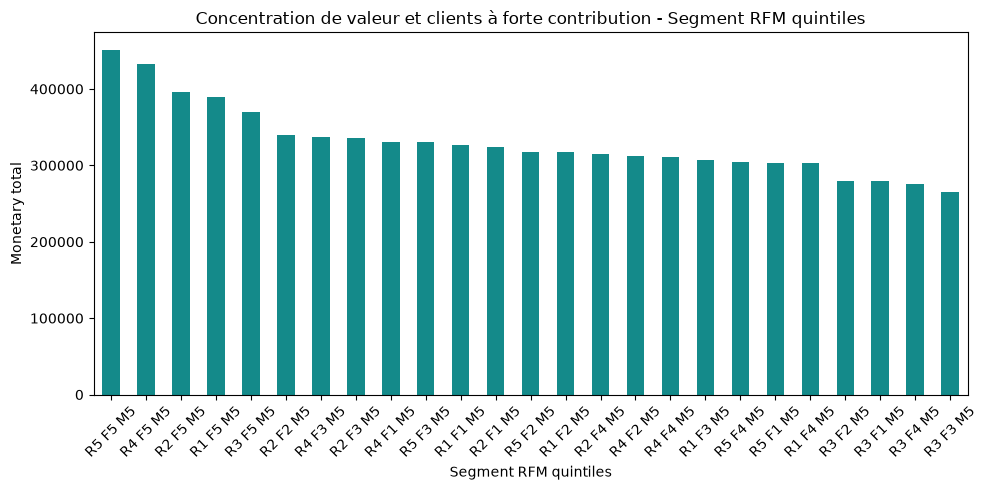

Visuel 2 - Concentration de valeur et clients à forte contribution - État client


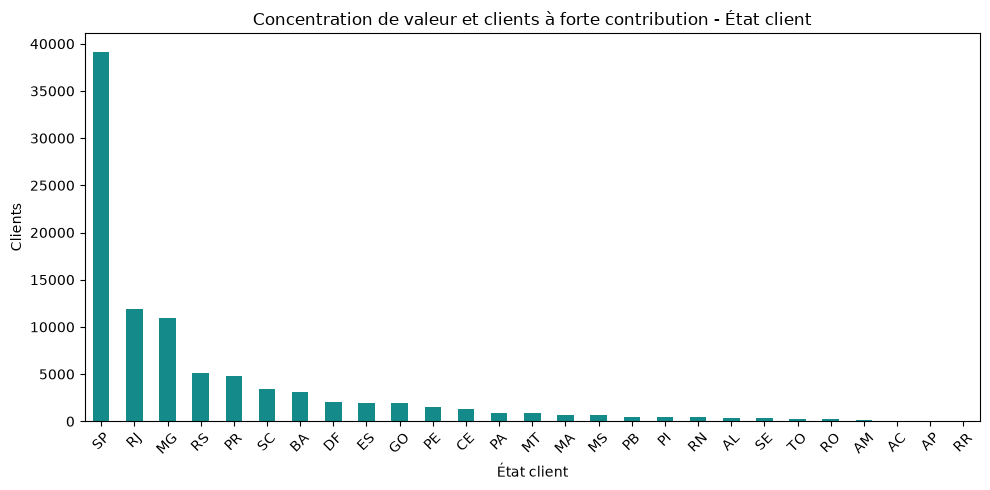

Visuel 3 - Concentration de valeur et clients à forte contribution - Ville client


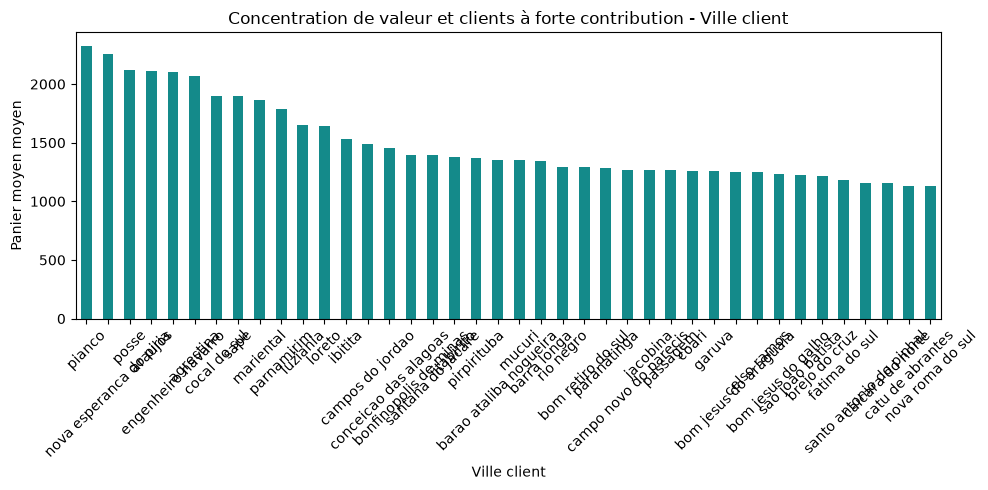

Visuel 4 - Concentration de valeur et clients à forte contribution - Code postal


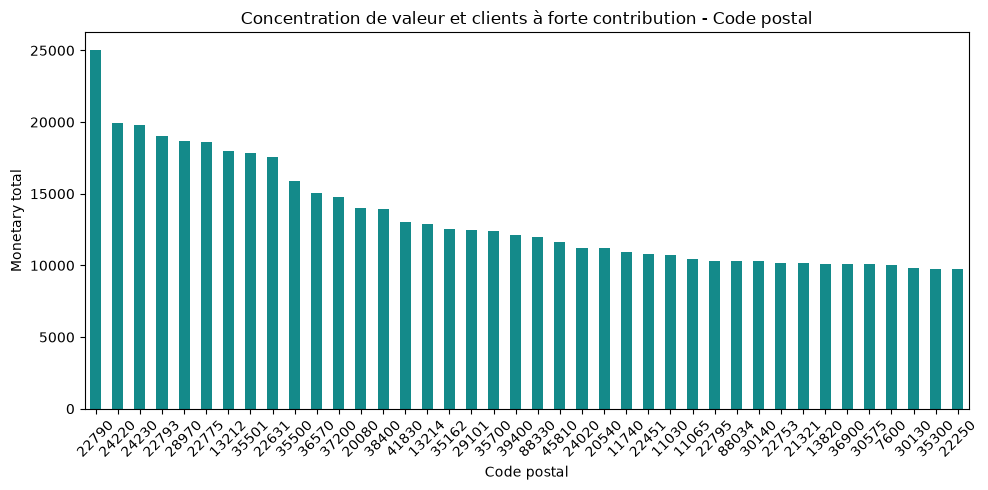

Visuel 5 - Concentration de valeur et clients à forte contribution - Fréquence


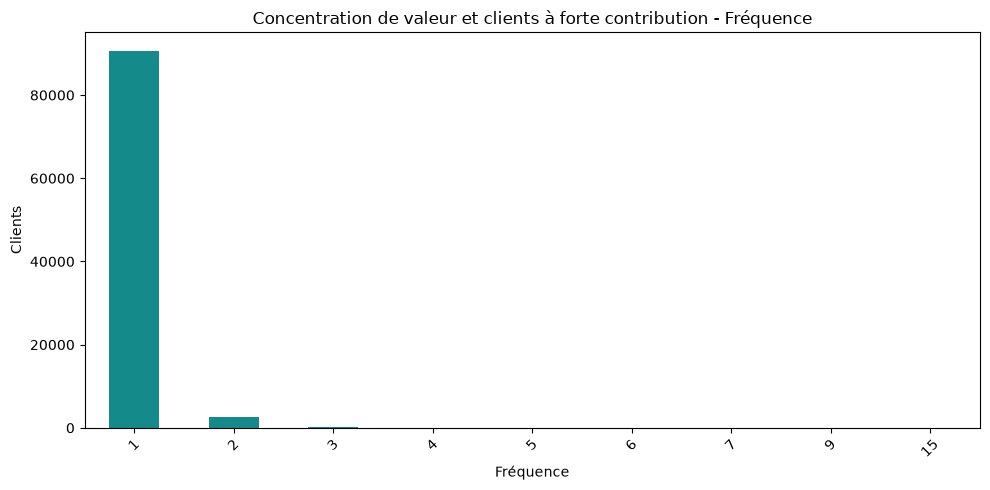

Visuel 6 - Concentration de valeur et clients à forte contribution - Récence


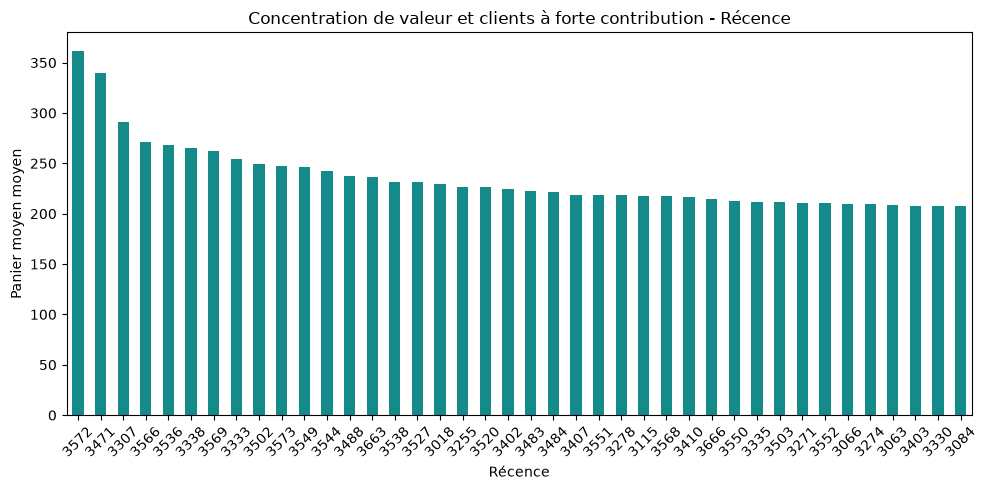

Visuel 7 - Concentration de valeur et clients à forte contribution - Dernier achat mois


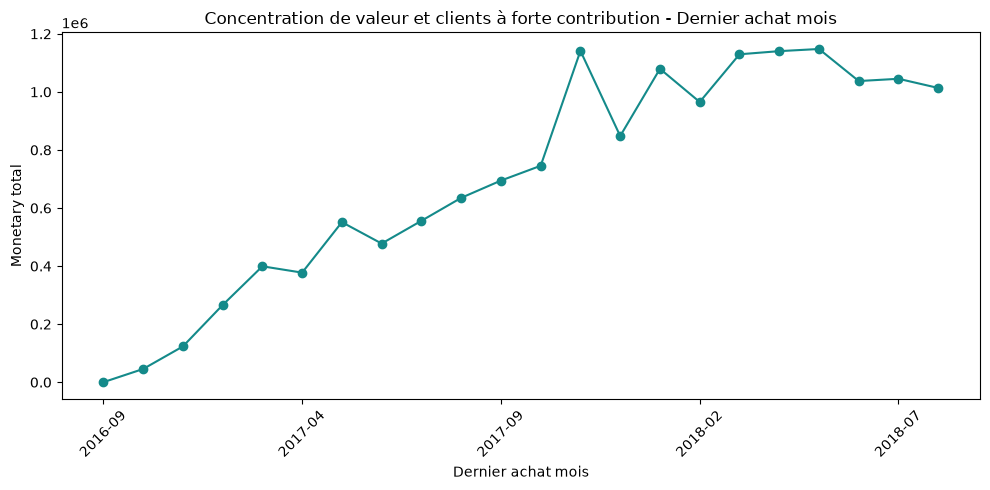

Visuel 8 - Concentration de valeur et clients à forte contribution - Monetary par tranche relative


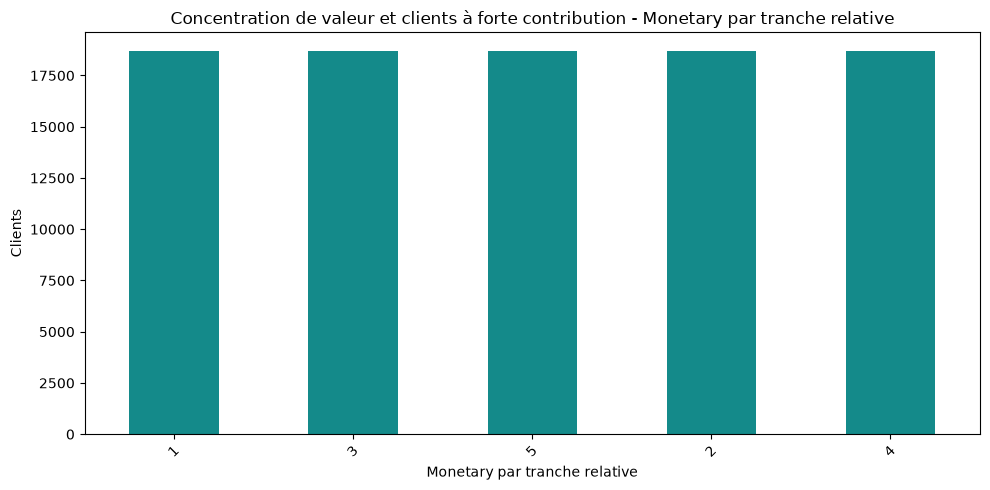

Visuel 9 - Concentration de valeur et clients à forte contribution - Segment x état


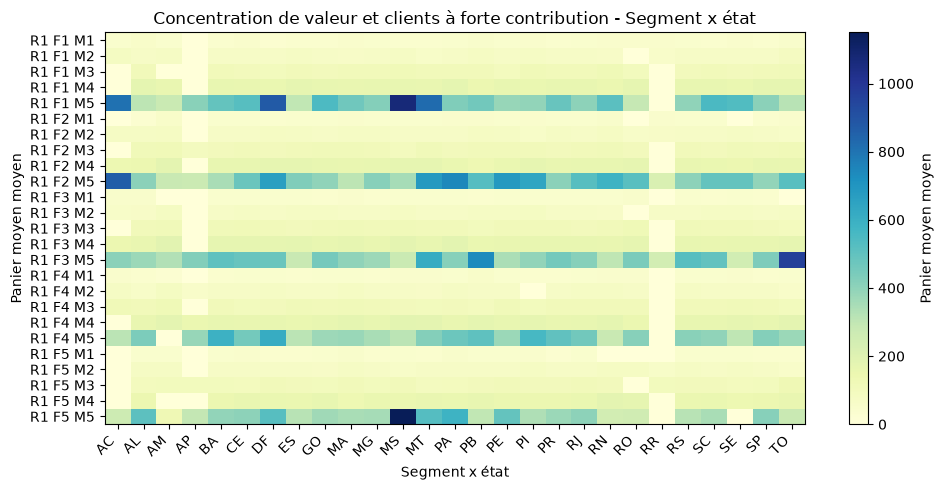

Visuel 10 - Concentration de valeur et clients à forte contribution - Segment x récence


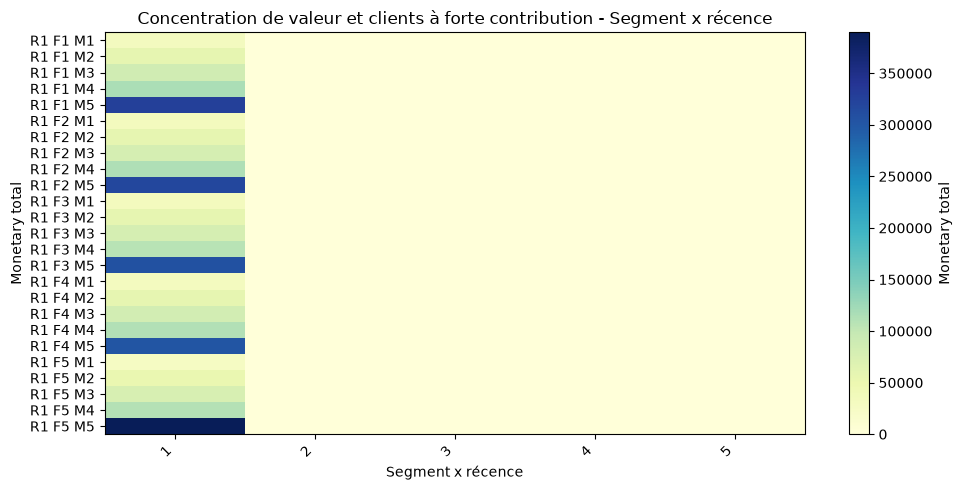

In [5]:
CHARTS=[
  {
    "n": 1,
    "title": "Concentration de valeur et clients à forte contribution - Segment RFM quintiles",
    "dim": {
      "label": "Segment RFM quintiles",
      "sql": "__rfm_segment",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Concentration de valeur et clients à forte contribution - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Concentration de valeur et clients à forte contribution - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Panier moyen moyen",
      "sql": "AVG(\"average_order_value\")",
      "pandas": "average_order_value"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Concentration de valeur et clients à forte contribution - Code postal",
    "dim": {
      "label": "Code postal",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Concentration de valeur et clients à forte contribution - Fréquence",
    "dim": {
      "label": "Fréquence",
      "sql": "\"frequency\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Concentration de valeur et clients à forte contribution - Récence",
    "dim": {
      "label": "Récence",
      "sql": "\"recency_days\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Panier moyen moyen",
      "sql": "AVG(\"average_order_value\")",
      "pandas": "average_order_value"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Concentration de valeur et clients à forte contribution - Dernier achat mois",
    "dim": {
      "label": "Dernier achat mois",
      "sql": "SUBSTRING(\"last_purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "line"
  },
  {
    "n": 8,
    "title": "Concentration de valeur et clients à forte contribution - Monetary par tranche relative",
    "dim": {
      "label": "Monetary par tranche relative",
      "sql": "__rfm_m_score",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Concentration de valeur et clients à forte contribution - Segment x état",
    "dim": {
      "label": "Segment x état",
      "sql": "__rfm_segment",
      "type": "client",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Panier moyen moyen",
      "sql": "AVG(\"average_order_value\")",
      "pandas": "average_order_value"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Concentration de valeur et clients à forte contribution - Segment x récence",
    "dim": {
      "label": "Segment x récence",
      "sql": "__rfm_segment",
      "type": "client",
      "series": "__rfm_r_score"
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 3. Récence et opportunités de réactivation

Décrire l’ancienneté du dernier achat livré et croiser la récence avec fréquence et valeur pour organiser des campagnes ciblées.

**Drill-down :** Récence > dernier mois d’achat > fréquence/Monetary > client; comparer état et ville.

Visuel 1 - Récence et opportunités de réactivation - Récence (jours)


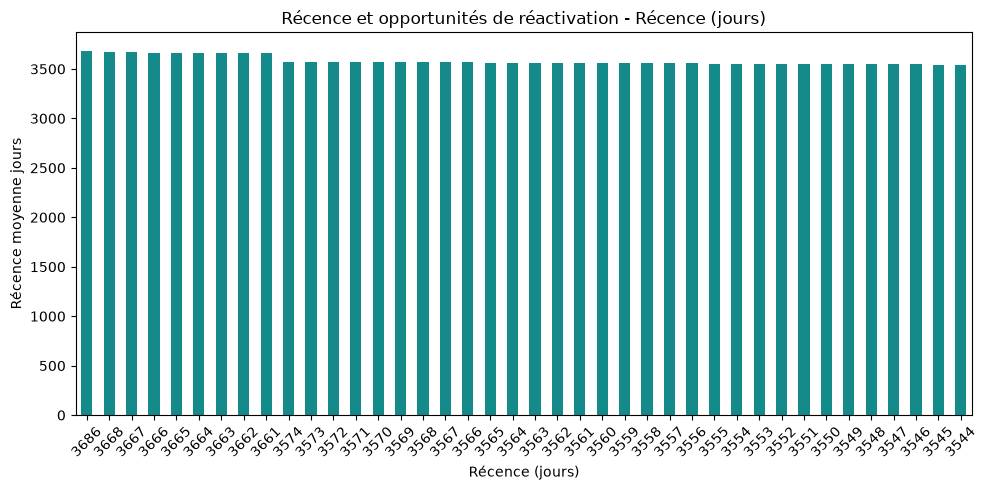

Visuel 2 - Récence et opportunités de réactivation - Mois dernier achat


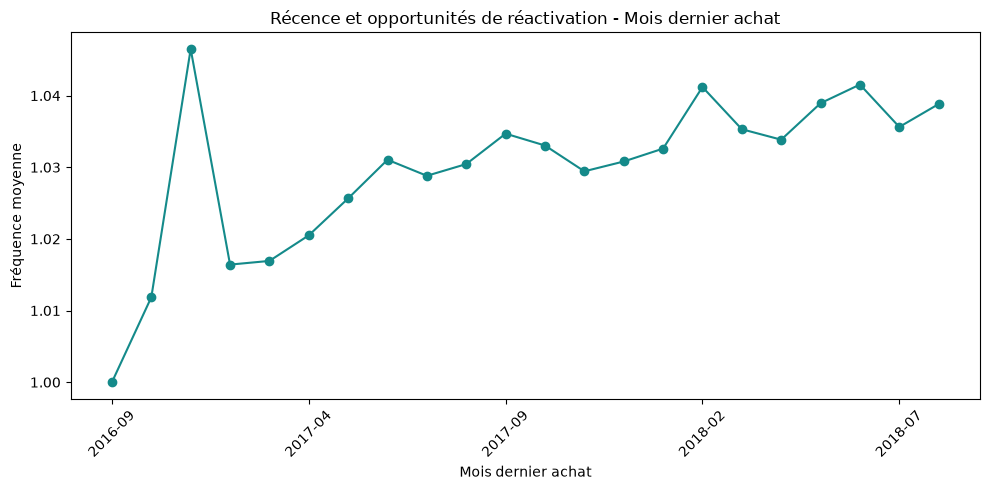

Visuel 3 - Récence et opportunités de réactivation - Année dernier achat


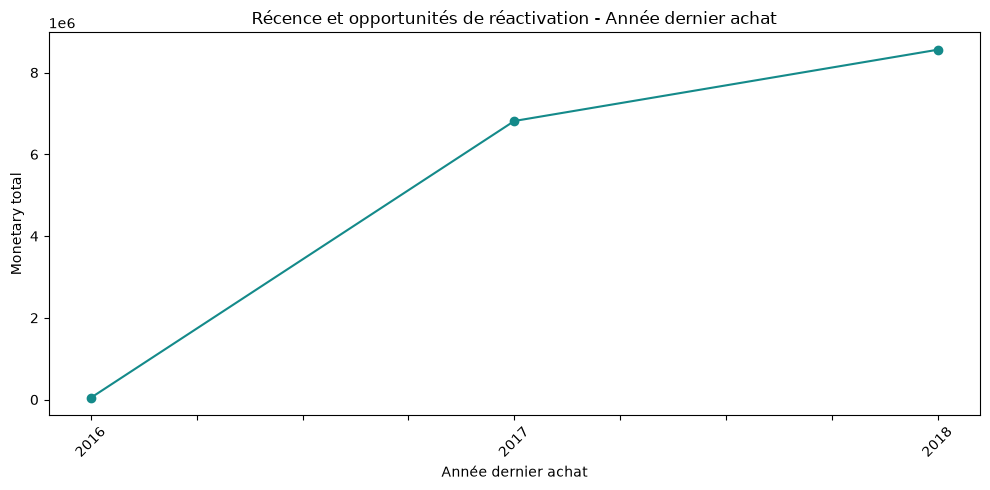

Visuel 4 - Récence et opportunités de réactivation - Partie du jour dernier achat


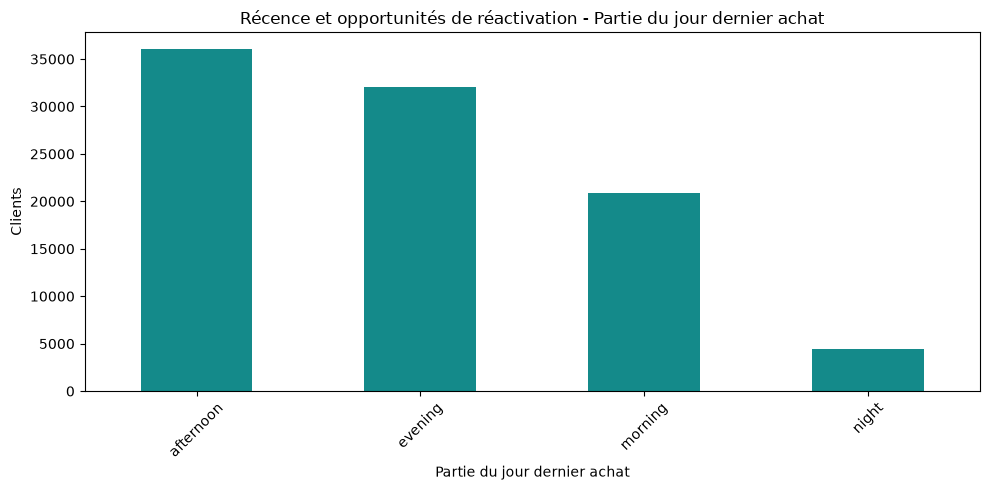

Visuel 5 - Récence et opportunités de réactivation - Score récence R


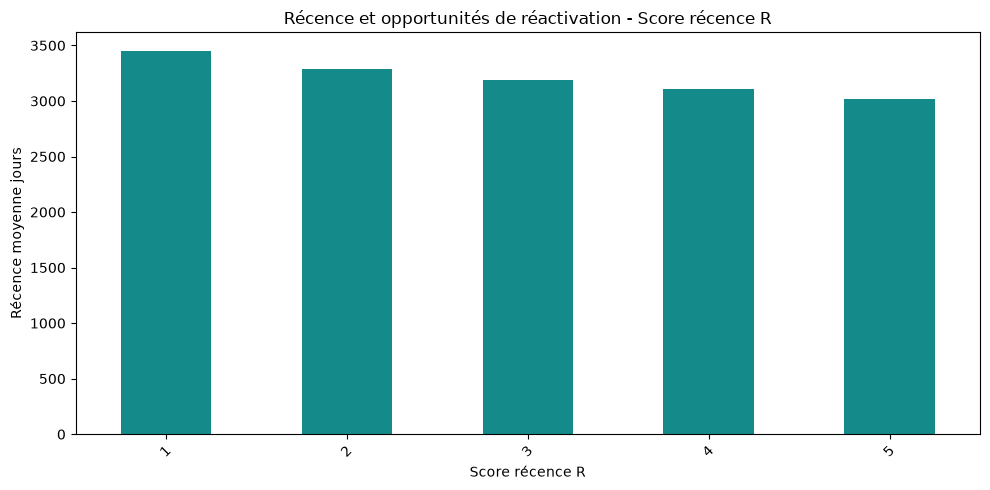

Visuel 6 - Récence et opportunités de réactivation - État client


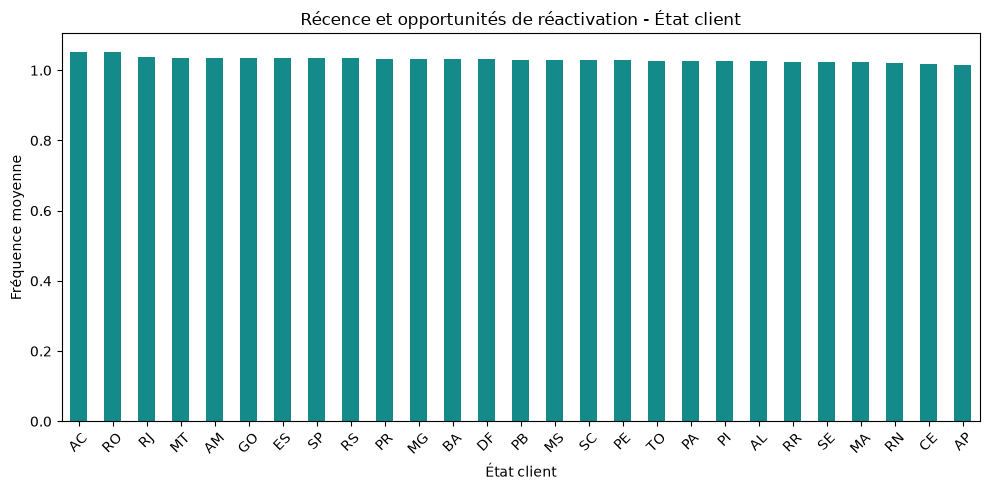

Visuel 7 - Récence et opportunités de réactivation - Ville client


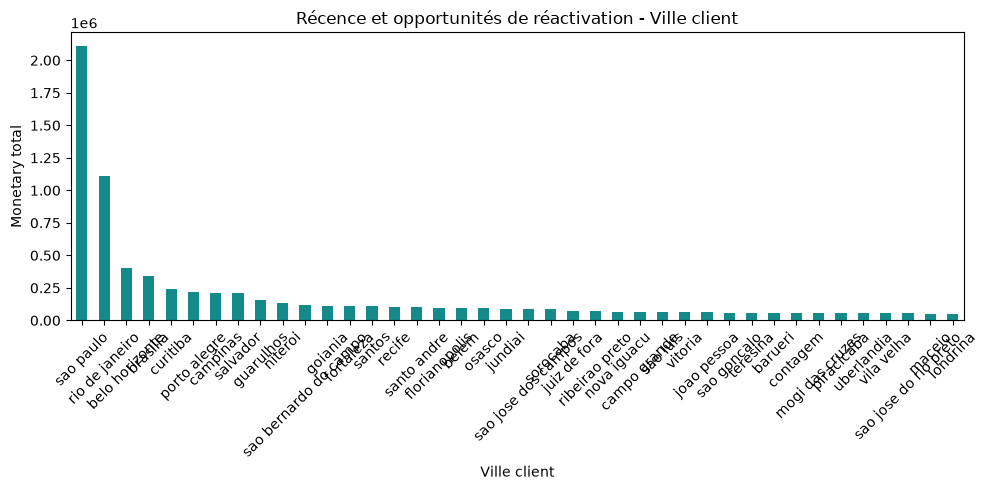

Visuel 8 - Récence et opportunités de réactivation - Récence x fréquence


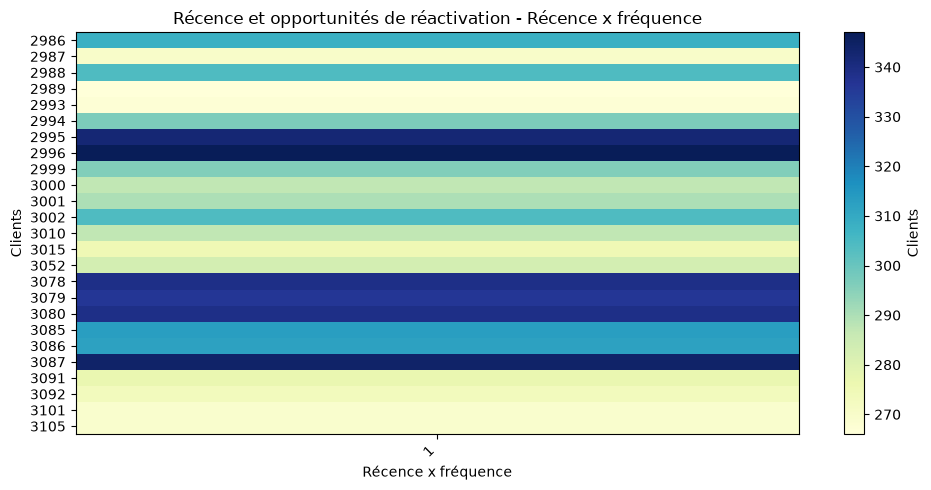

Visuel 9 - Récence et opportunités de réactivation - Récence x Monetary score


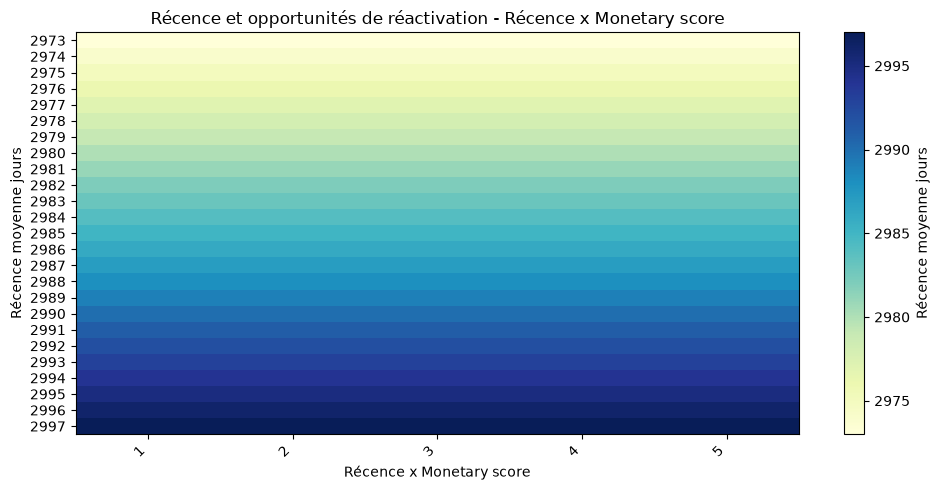

Visuel 10 - Récence et opportunités de réactivation - Segment x mois dernier achat


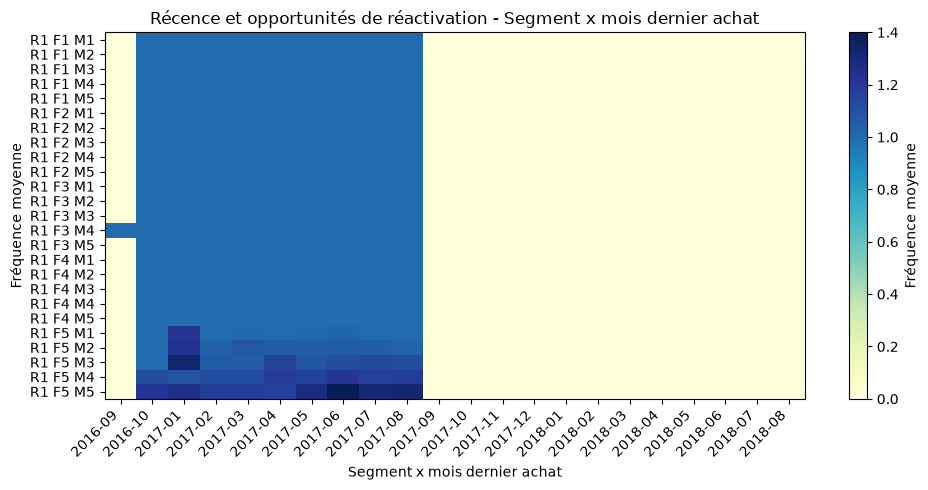

In [6]:
CHARTS=[
  {
    "n": 1,
    "title": "Récence et opportunités de réactivation - Récence (jours)",
    "dim": {
      "label": "Récence (jours)",
      "sql": "\"recency_days\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Récence moyenne jours",
      "sql": "AVG(\"recency_days\")",
      "pandas": "recency_days"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Récence et opportunités de réactivation - Mois dernier achat",
    "dim": {
      "label": "Mois dernier achat",
      "sql": "SUBSTRING(\"last_purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Récence et opportunités de réactivation - Année dernier achat",
    "dim": {
      "label": "Année dernier achat",
      "sql": "\"last_purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "line"
  },
  {
    "n": 4,
    "title": "Récence et opportunités de réactivation - Partie du jour dernier achat",
    "dim": {
      "label": "Partie du jour dernier achat",
      "sql": "\"last_purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Récence et opportunités de réactivation - Score récence R",
    "dim": {
      "label": "Score récence R",
      "sql": "__rfm_r_score",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Récence moyenne jours",
      "sql": "AVG(\"recency_days\")",
      "pandas": "recency_days"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Récence et opportunités de réactivation - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Récence et opportunités de réactivation - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Récence et opportunités de réactivation - Récence x fréquence",
    "dim": {
      "label": "Récence x fréquence",
      "sql": "\"recency_days\"",
      "type": "numeric",
      "series": "\"frequency\""
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Récence et opportunités de réactivation - Récence x Monetary score",
    "dim": {
      "label": "Récence x Monetary score",
      "sql": "\"recency_days\"",
      "type": "numeric",
      "series": "__rfm_m_score"
    },
    "metric": {
      "label": "Récence moyenne jours",
      "sql": "AVG(\"recency_days\")",
      "pandas": "recency_days"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Récence et opportunités de réactivation - Segment x mois dernier achat",
    "dim": {
      "label": "Segment x mois dernier achat",
      "sql": "__rfm_segment",
      "type": "client",
      "series": "SUBSTRING(\"last_purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 4. Fréquence d’achat et valeur relationnelle

Comparer nombre de commandes livrées et valeur cumulée par client pour repérer fidélité transactionnelle et valeur économique.

**Drill-down :** Fréquence > Monetary > panier moyen > segment client; état > ville > code postal.

Visuel 1 - Fréquence d’achat et valeur relationnelle - Fréquence


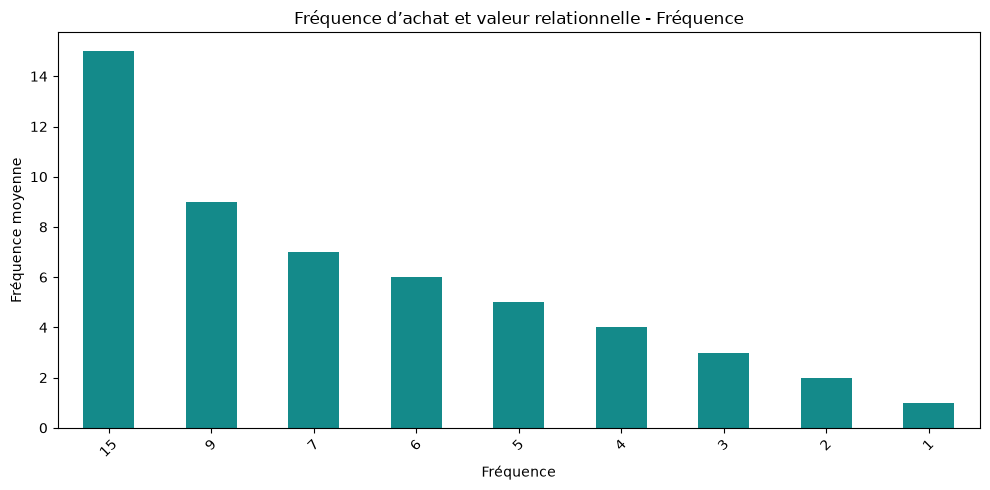

Visuel 2 - Fréquence d’achat et valeur relationnelle - Monetary


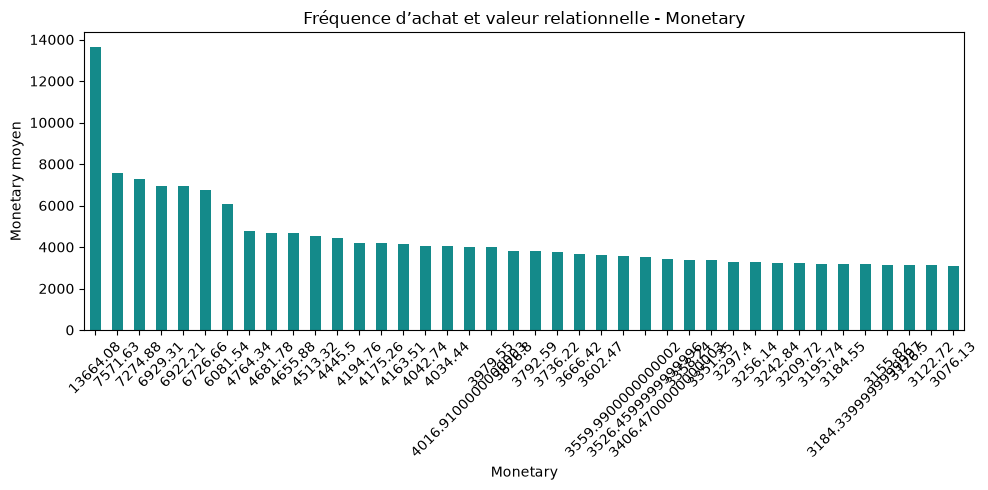

Visuel 3 - Fréquence d’achat et valeur relationnelle - Panier moyen client


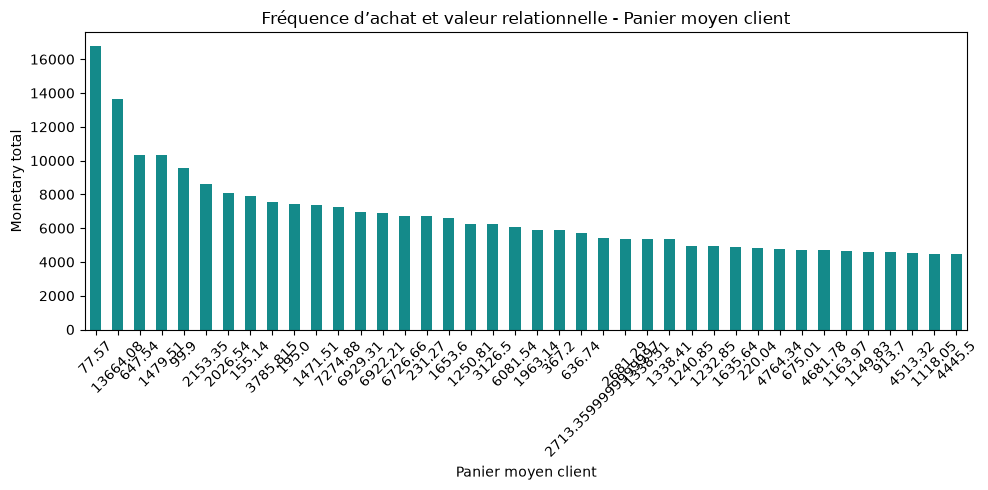

Visuel 4 - Fréquence d’achat et valeur relationnelle - Segment RFM


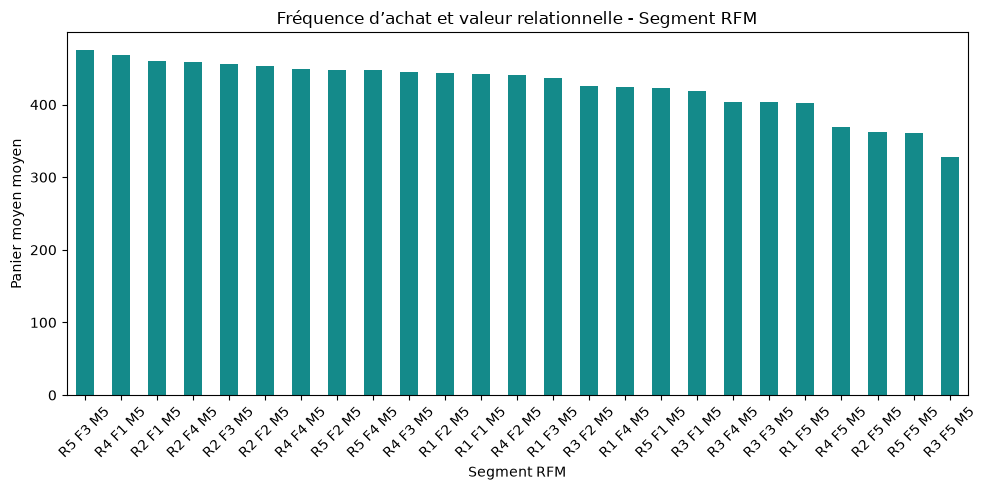

Visuel 5 - Fréquence d’achat et valeur relationnelle - État client


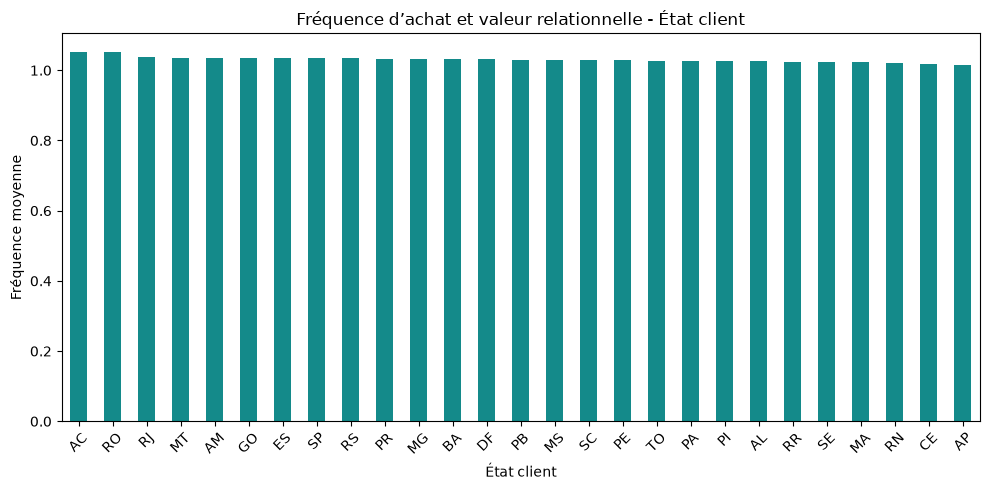

Visuel 6 - Fréquence d’achat et valeur relationnelle - Ville client


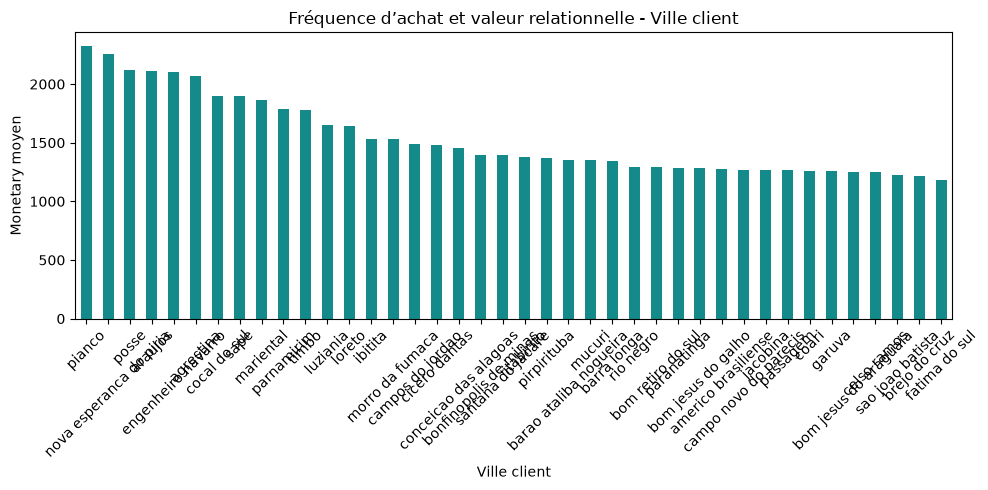

Visuel 7 - Fréquence d’achat et valeur relationnelle - Code postal


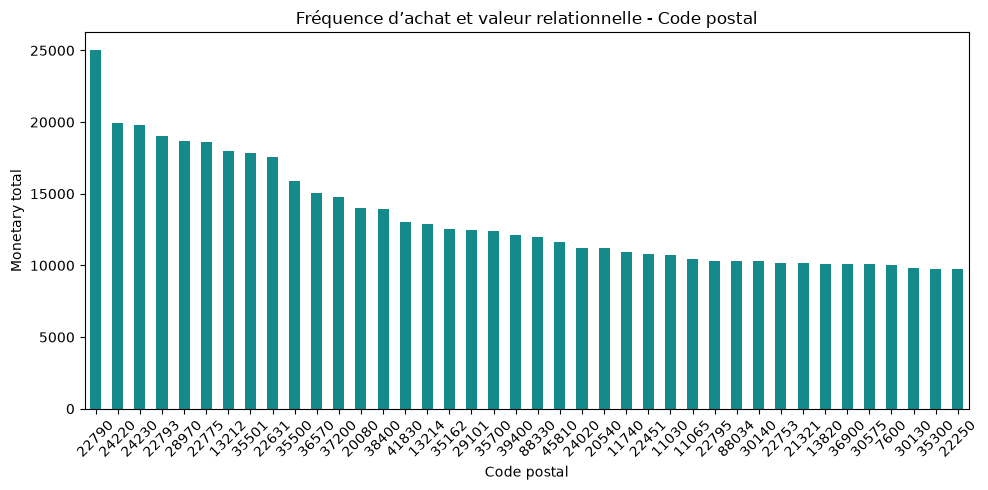

Visuel 8 - Fréquence d’achat et valeur relationnelle - Récence


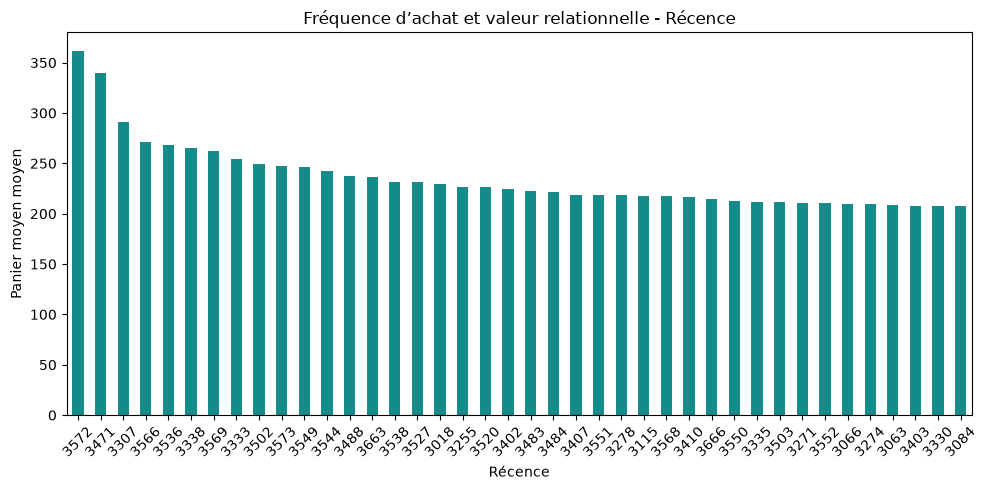

Visuel 9 - Fréquence d’achat et valeur relationnelle - Fréquence x Monetary


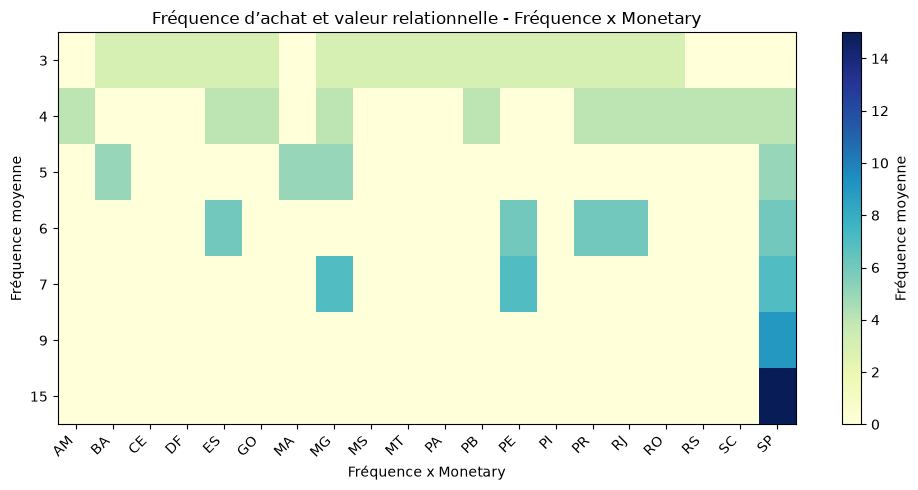

Visuel 10 - Fréquence d’achat et valeur relationnelle - Segment x état


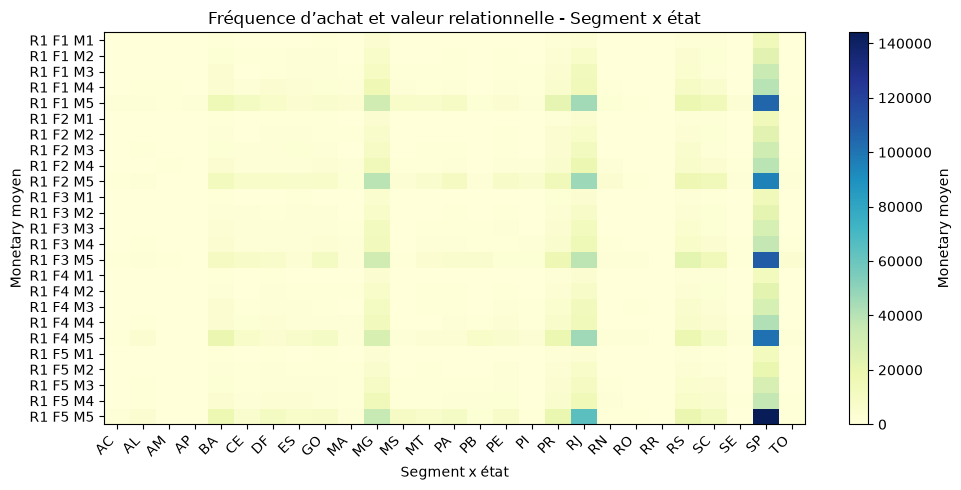

In [7]:
CHARTS=[
  {
    "n": 1,
    "title": "Fréquence d’achat et valeur relationnelle - Fréquence",
    "dim": {
      "label": "Fréquence",
      "sql": "\"frequency\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Fréquence d’achat et valeur relationnelle - Monetary",
    "dim": {
      "label": "Monetary",
      "sql": "\"monetary\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Monetary moyen",
      "sql": "AVG(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Fréquence d’achat et valeur relationnelle - Panier moyen client",
    "dim": {
      "label": "Panier moyen client",
      "sql": "\"average_order_value\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Fréquence d’achat et valeur relationnelle - Segment RFM",
    "dim": {
      "label": "Segment RFM",
      "sql": "__rfm_segment",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Panier moyen moyen",
      "sql": "AVG(\"average_order_value\")",
      "pandas": "average_order_value"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Fréquence d’achat et valeur relationnelle - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Fréquence d’achat et valeur relationnelle - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Monetary moyen",
      "sql": "AVG(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Fréquence d’achat et valeur relationnelle - Code postal",
    "dim": {
      "label": "Code postal",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Fréquence d’achat et valeur relationnelle - Récence",
    "dim": {
      "label": "Récence",
      "sql": "\"recency_days\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Panier moyen moyen",
      "sql": "AVG(\"average_order_value\")",
      "pandas": "average_order_value"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Fréquence d’achat et valeur relationnelle - Fréquence x Monetary",
    "dim": {
      "label": "Fréquence x Monetary",
      "sql": "\"frequency\"",
      "type": "numeric",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Fréquence d’achat et valeur relationnelle - Segment x état",
    "dim": {
      "label": "Segment x état",
      "sql": "__rfm_segment",
      "type": "client",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Monetary moyen",
      "sql": "AVG(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 5. Géographie et profils clients

Comparer la distribution des profils RFM par état, ville et code postal, en conservant les effectifs pour contextualiser les petits segments.

**Drill-down :** État > ville > code postal; segment RFM > client; dernier achat par mois disponible.

Visuel 1 - Géographie et profils clients - État client


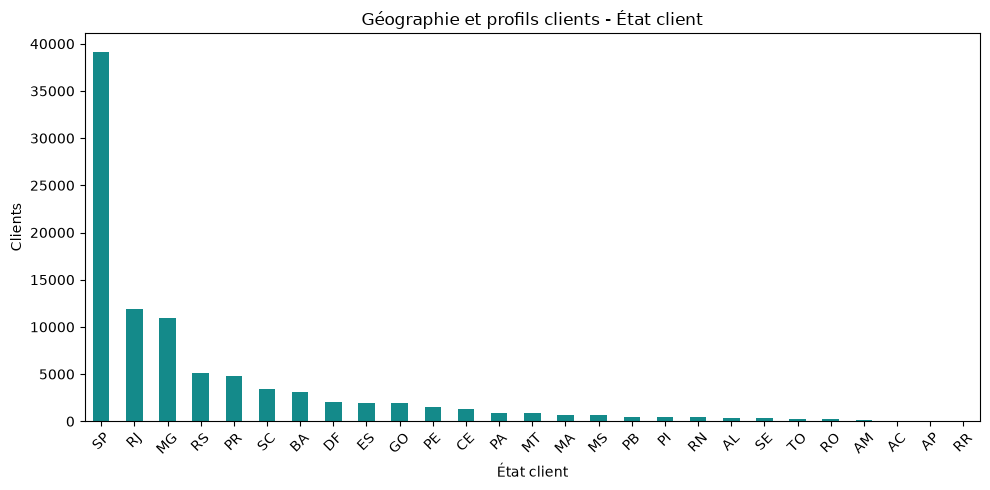

Visuel 2 - Géographie et profils clients - Ville client


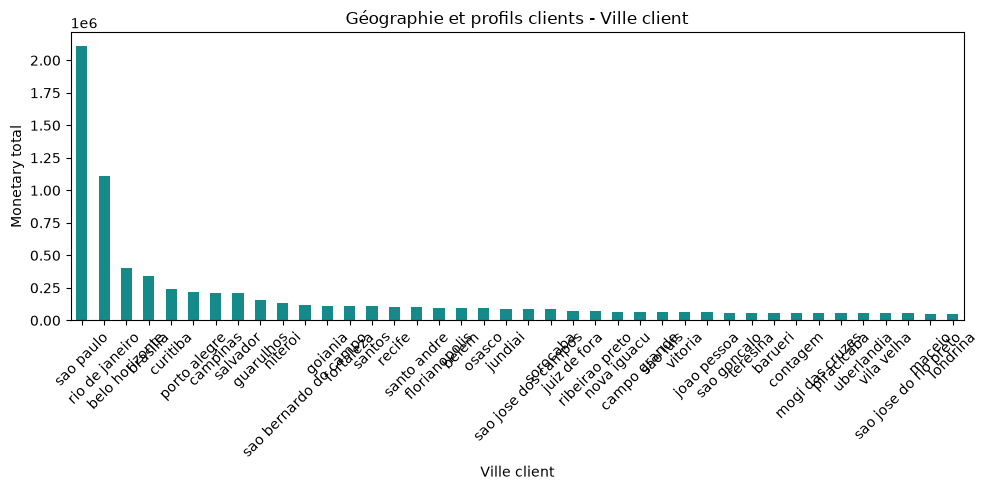

Visuel 3 - Géographie et profils clients - Code postal


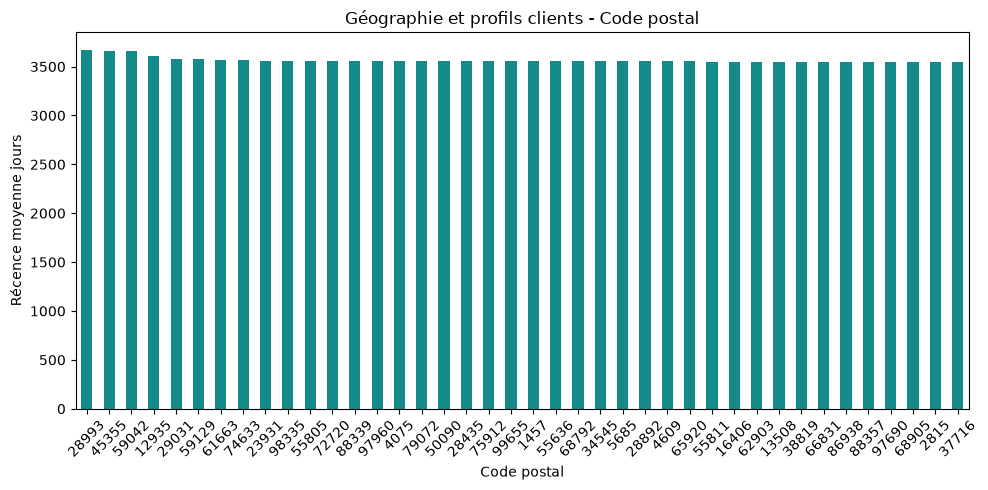

Visuel 4 - Géographie et profils clients - État x segment


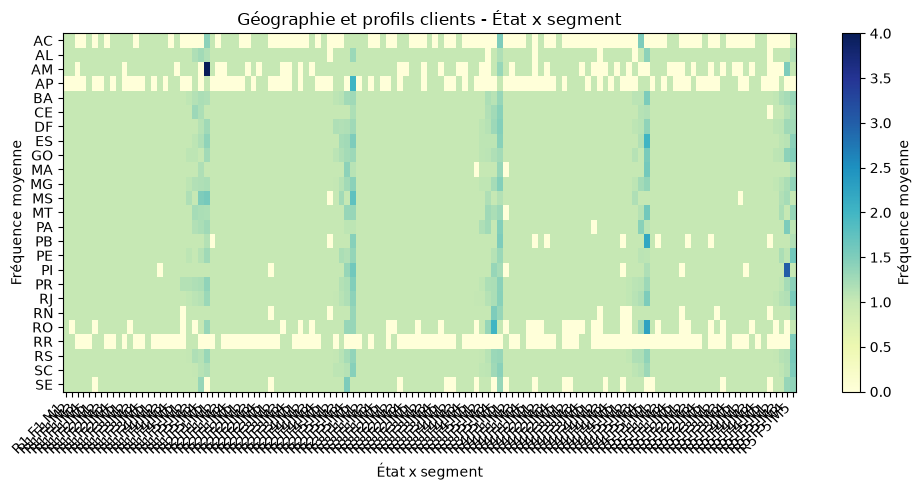

Visuel 5 - Géographie et profils clients - Ville x segment


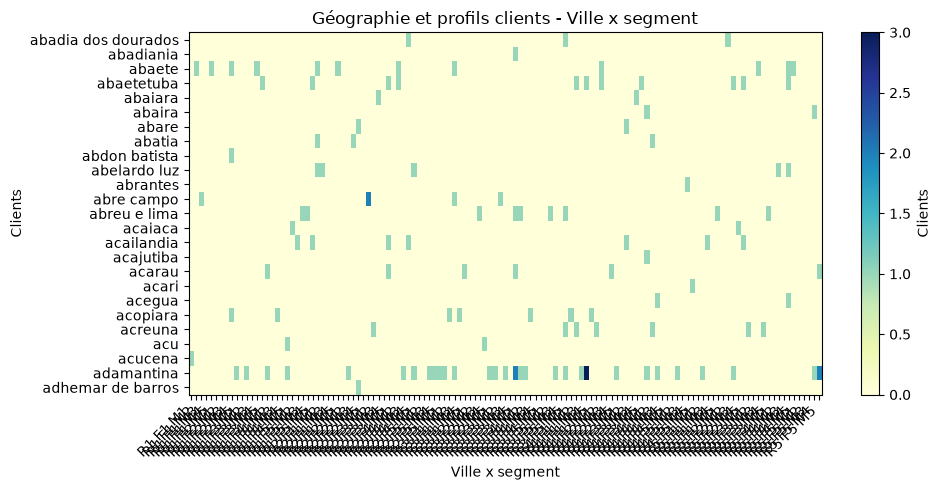

Visuel 6 - Géographie et profils clients - État x mois dernier achat


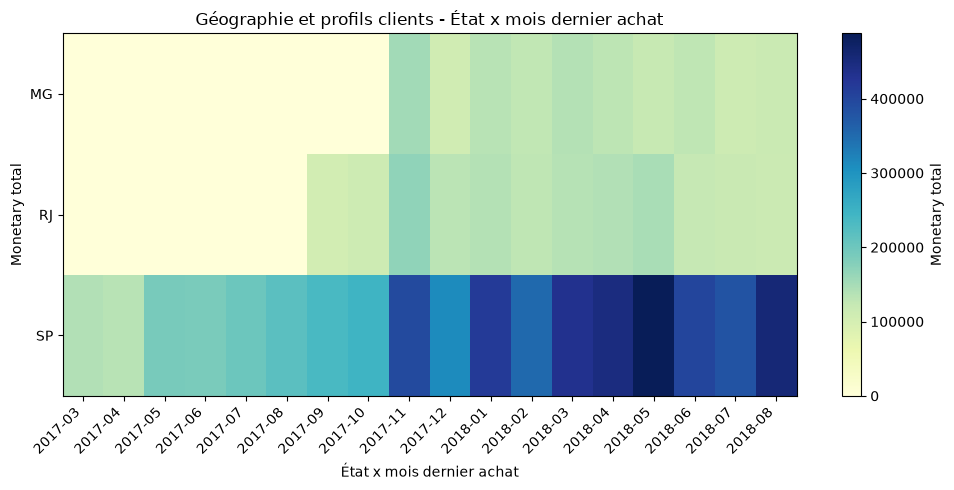

Visuel 7 - Géographie et profils clients - Monetary x état


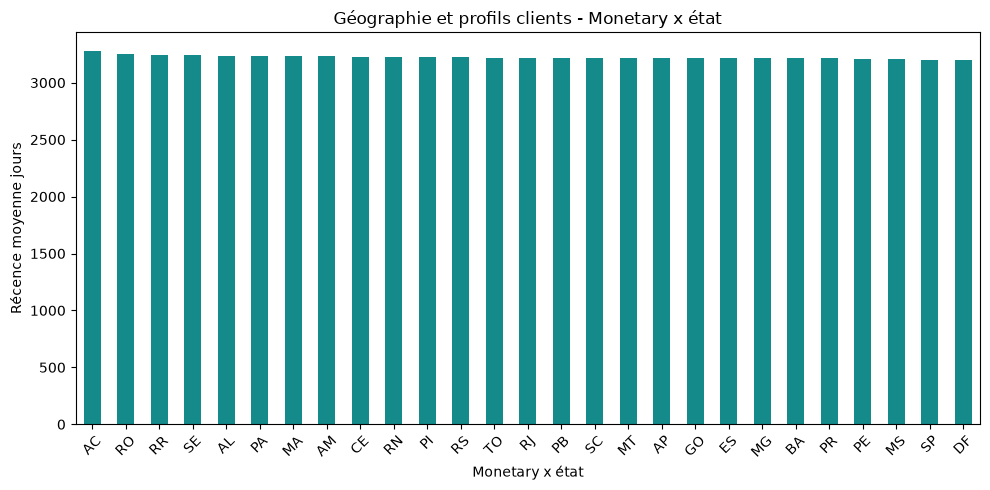

Visuel 8 - Géographie et profils clients - Récence x ville


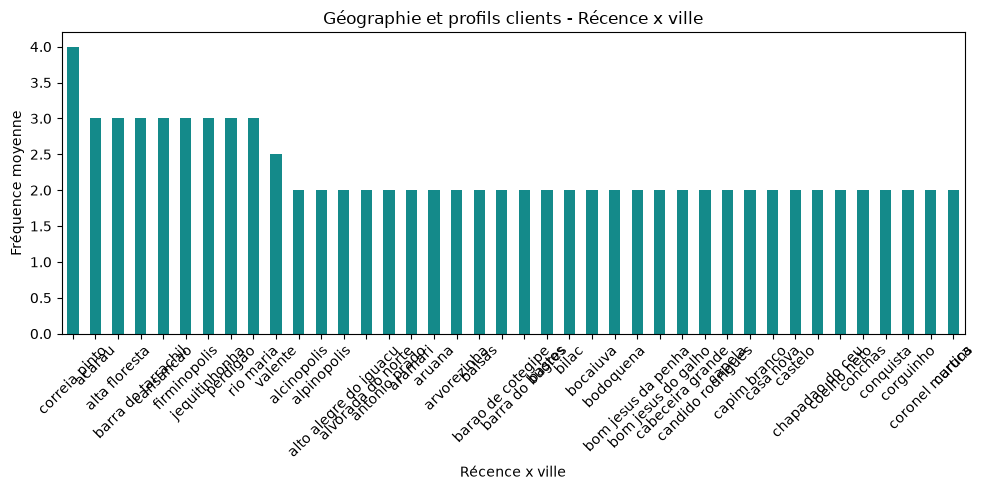

Visuel 9 - Géographie et profils clients - Dernier achat mois


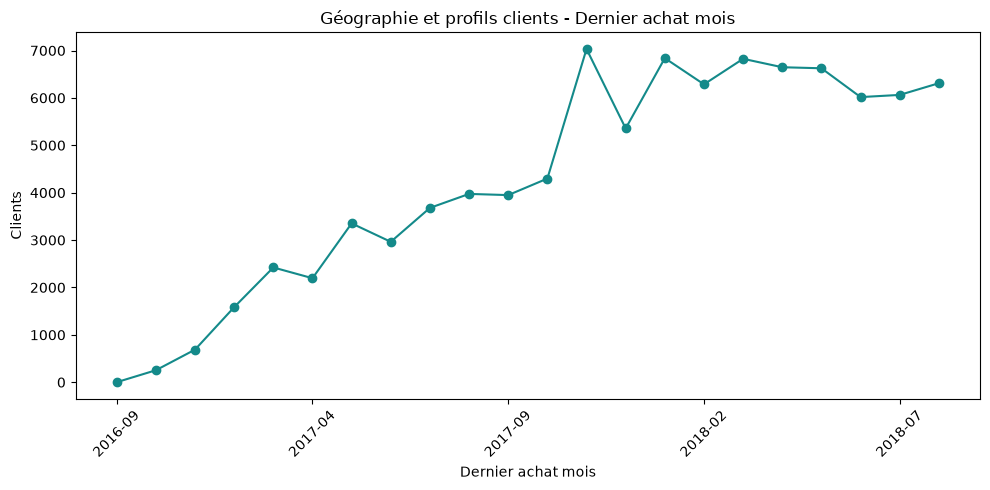

Visuel 10 - Géographie et profils clients - Segment RFM


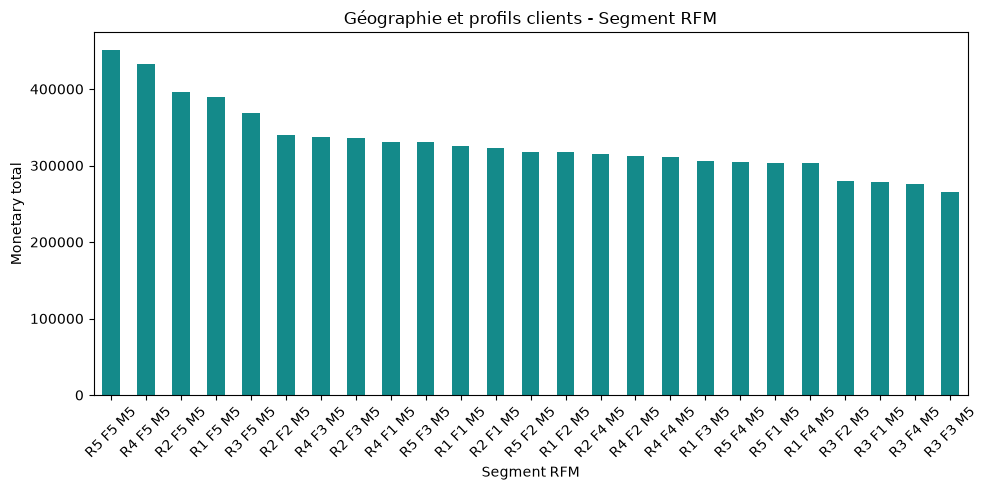

In [8]:
CHARTS=[
  {
    "n": 1,
    "title": "Géographie et profils clients - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Géographie et profils clients - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Géographie et profils clients - Code postal",
    "dim": {
      "label": "Code postal",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Récence moyenne jours",
      "sql": "AVG(\"recency_days\")",
      "pandas": "recency_days"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Géographie et profils clients - État x segment",
    "dim": {
      "label": "État x segment",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "__rfm_segment"
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "heatmap"
  },
  {
    "n": 5,
    "title": "Géographie et profils clients - Ville x segment",
    "dim": {
      "label": "Ville x segment",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": "__rfm_segment"
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "heatmap"
  },
  {
    "n": 6,
    "title": "Géographie et profils clients - État x mois dernier achat",
    "dim": {
      "label": "État x mois dernier achat",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "SUBSTRING(\"last_purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "heatmap"
  },
  {
    "n": 7,
    "title": "Géographie et profils clients - Monetary x état",
    "dim": {
      "label": "Monetary x état",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Récence moyenne jours",
      "sql": "AVG(\"recency_days\")",
      "pandas": "recency_days"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Géographie et profils clients - Récence x ville",
    "dim": {
      "label": "Récence x ville",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Fréquence moyenne",
      "sql": "AVG(\"frequency\")",
      "pandas": "frequency"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Géographie et profils clients - Dernier achat mois",
    "dim": {
      "label": "Dernier achat mois",
      "sql": "SUBSTRING(\"last_purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Clients",
      "sql": "COUNT(*)",
      "pandas": "customer_unique_id"
    },
    "kind": "line"
  },
  {
    "n": 10,
    "title": "Géographie et profils clients - Segment RFM",
    "dim": {
      "label": "Segment RFM",
      "sql": "__rfm_segment",
      "type": "client",
      "series": None
    },
    "metric": {
      "label": "Monetary total",
      "sql": "SUM(\"monetary\")",
      "pandas": "monetary"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## Lecture des résultats\n\nComparer les valeurs aux volumes, vérifier les petits effectifs et suivre les chemins de drill-down du dossier. Les ratios et moyennes se recalculent au niveau affiché. Une association ne démontre pas une causalité.